##IMPORT LIBRARIES

## DATA ANALYSIS OF BLINKIT

In [101]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

## IMPORT RAW DATA

In [70]:
df = pd.read_csv("C:/Users/kfb26178/OneDrive - University of Strathclyde/BLINKIT_PROJECT/blinkit_data.csv")

# SAMPLE DATA

In [71]:
df.head(10)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2010,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2000,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0
5,low fat,FDS52,Frozen Foods,2020,OUT017,Tier 2,Small,Supermarket Type1,0.005505,8.89,102.4016,5.0
6,Low Fat,NCU05,Health and Hygiene,2011,OUT010,Tier 3,Small,Grocery Store,0.098312,11.80,81.4618,5.0
7,Low Fat,NCD30,Household,2015,OUT045,Tier 2,Small,Supermarket Type1,0.026904,19.70,96.0726,5.0
8,Low Fat,FDW20,Fruits and Vegetables,2000,OUT013,Tier 3,High,Supermarket Type1,0.024129,20.75,124.1730,5.0
9,Low Fat,FDX25,Canned,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.101562,NaN,181.9292,5.0


In [72]:
df.tail(10)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
8513,Regular,DRY23,Soft Drinks,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.108568,NaN,42.9112,4.0
8514,low fat,FDA11,Baking Goods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.043029,NaN,94.7436,4.0
8515,low fat,FDK38,Canned,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.053032,NaN,149.1734,4.0
8516,low fat,FDO38,Canned,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.072486,NaN,78.9986,4.0
8517,low fat,FDG32,Fruits and Vegetables,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.175143,NaN,222.3772,4.0
8518,low fat,NCT53,Health and Hygiene,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,164.5526,4.0
8519,low fat,FDN09,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.034706,NaN,241.6828,4.0
8520,low fat,DRE13,Soft Drinks,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.027571,NaN,86.6198,4.0
8521,reg,FDT50,Dairy,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.107715,NaN,97.8752,4.0
8522,reg,FDM58,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,112.2544,4.0


# size of DATA

In [73]:
print("size of data", df.shape)

size of data (8523, 12)


# Field Info

In [74]:
df.columns

Index(['Item Fat Content', 'Item Identifier', 'Item Type',
       'Outlet Establishment Year', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility',
       'Item Weight', 'Sales', 'Rating'],
      dtype='object')

# data types

In [75]:
df.dtypes

Item Fat Content              object
Item Identifier               object
Item Type                     object
Outlet Establishment Year      int64
Outlet Identifier             object
Outlet Location Type          object
Outlet Size                   object
Outlet Type                   object
Item Visibility              float64
Item Weight                  float64
Sales                        float64
Rating                       float64
dtype: object

In [76]:
df.describe()

,Outlet Establishment Year,Item Visibility,Item Weight,Sales,Rating
count,8523.000000,8523.000000,7060.000000,8523.000000,8523.000000
mean,2010.831867,0.066132,12.857645,140.992782,3.965857
std,8.371760,0.051598,4.643456,62.275067,0.605651
min,1998.000000,0.000000,4.555000,31.290000,1.000000
25%,2000.000000,0.026989,8.773750,93.826500,4.000000
50%,2012.000000,0.053931,12.600000,143.012800,4.000000
75%,2017.000000,0.094585,16.850000,185.643700,4.200000
max,2022.000000,0.328391,21.350000,266.888400,5.000000


In [77]:
df.describe(include=['O'])

,Item Fat Content,Item Identifier,Item Type,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type
count,8523,8523,8523,8523,8523,8523,8523
unique,5,1559,16,10,3,3,4
top,Low Fat,FDW13,Fruits and Vegetables,OUT027,Tier 3,Medium,Supermarket Type1
freq,5089,10,1232,935,3350,3631,5577


# data cleaning

In [78]:
print(df['Item Fat Content'].unique())

['Regular' 'Low Fat' 'low fat' 'LF' 'reg']


In [79]:
df['Item Fat Content']=df['Item Fat Content'].replace({'LF':'Low Fat',
                                                       'low fat':'Low Fat',
                                                       'reg': 'Regular'})

In [80]:
print(df['Item Fat Content'].unique())

['Regular' 'Low Fat']


In [81]:
print(df['Item Fat Content'].value_counts())

Item Fat Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64


### filling missing value

In [82]:
df.isnull().sum()

Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64

In [83]:
median_weight=df['Item Weight'].median()

In [84]:
df['Item Weight']=df['Item Weight'].fillna(median_weight)

In [85]:
df.isnull().sum()

Item Fat Content             0
Item Identifier              0
Item Type                    0
Outlet Establishment Year    0
Outlet Identifier            0
Outlet Location Type         0
Outlet Size                  0
Outlet Type                  0
Item Visibility              0
Item Weight                  0
Sales                        0
Rating                       0
dtype: int64

## Outlet Age

In [88]:
current_year=2026
df['outlet_age']=current_year-df['Outlet Establishment Year']

In [89]:
print(df[['Outlet Establishment Year','outlet_age']].head())

   Outlet Establishment Year  outlet_age
0                       2012          14
1                       2022           4
2                       2010          16
3                       2000          26
4                       2015          11


In [90]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                8523 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
 12  outlet_age                 8523 non-null   int64  
dtypes: float64(4), int64(2), object(7)
memory usage:

In [91]:
print(df.describe())

       Outlet Establishment Year  Item Visibility  Item Weight        Sales  \
count                8523.000000      8523.000000   8523.00000  8523.000000   
mean                 2010.831867         0.066132     12.81342   140.992782   
std                     8.371760         0.051598      4.22724    62.275067   
min                  1998.000000         0.000000      4.55500    31.290000   
25%                  2000.000000         0.026989      9.31000    93.826500   
50%                  2012.000000         0.053931     12.60000   143.012800   
75%                  2017.000000         0.094585     16.00000   185.643700   
max                  2022.000000         0.328391     21.35000   266.888400   

            Rating   outlet_age  
count  8523.000000  8523.000000  
mean      3.965857    15.168133  
std       0.605651     8.371760  
min       1.000000     4.000000  
25%       4.000000     9.000000  
50%       4.000000    14.000000  
75%       4.200000    26.000000  
max       5.0000

# business 

# kpi requirements

In [29]:
# Total Sales
total_sales=df['Sales'].sum()

#Average Sales
avg_sales=df['Sales'].mean()

#No. of item sold
no_of_item_sold=df['Sales'].count()

#Average rating
avg_ratings=df['Rating'].mean()
 #display
print(f"Total Sales: ${total_sales:,.1f}")
print(f"Average Sales: ${avg_sales:,.1f}")
print(f"Total item sold: {no_of_item_sold:,.1f}")
print(f"Average rating Sales: {avg_ratings:,.1f}")

Total Sales: $1,201,681.5
Average Sales: $141.0
Total item sold: 8,523.0
Average rating Sales: 4.0


# charts requirements

# Total sales by Fat Content

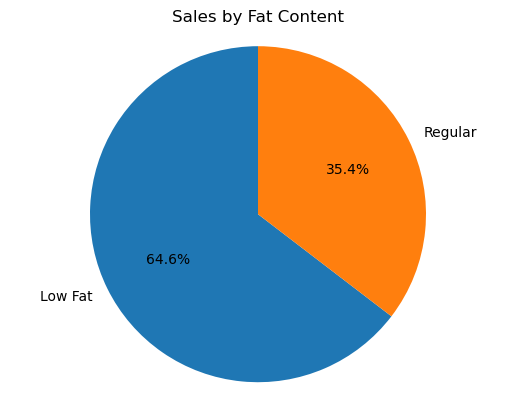

In [35]:
sales_by_fat=df.groupby('Item Fat Content')['Sales'].sum()
plt.pie(sales_by_fat, labels = sales_by_fat.index,
                        autopct='%.1f%%',
                        startangle=90)
plt.title('Sales by Fat Content')
plt.axis('equal')
plt.show()

# Total sales by Item Type

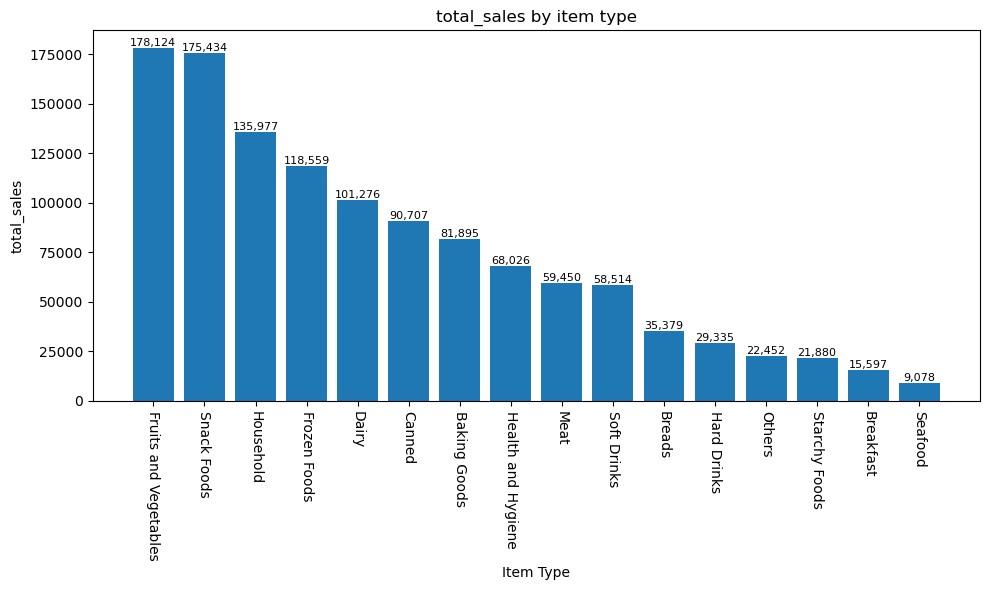

In [41]:
sales_by_type=df.groupby('Item Type')['Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(10,6))
bars=plt.bar(sales_by_type.index, sales_by_type.values)

plt.xticks(rotation=-90)
plt.xlabel('Item Type')
plt.ylabel('total_sales')
plt.title('total_sales by item type')

for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f'{bar.get_height():,.0f}',ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.show()

# Fat content by outlet for total sales

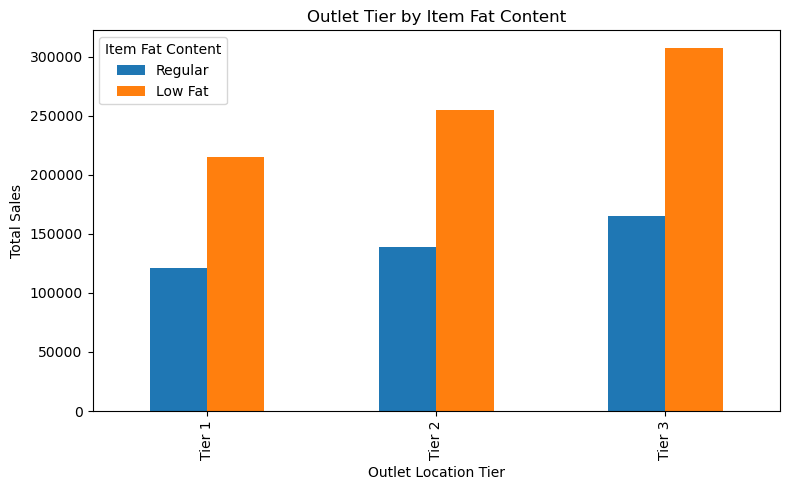

In [43]:
grouped=df.groupby(['Outlet Location Type', 'Item Fat Content'])['Sales'].sum().unstack()
grouped=grouped[['Regular','Low Fat']]

ax=grouped.plot(kind='bar', figsize=(8,5), title='Outlet Tier by Item Fat Content')
plt.xlabel('Outlet Location Tier')
plt.ylabel('Total Sales')
plt.legend(title='Item Fat Content')
plt.tight_layout()
plt.show()

# total sales by outlate establishment

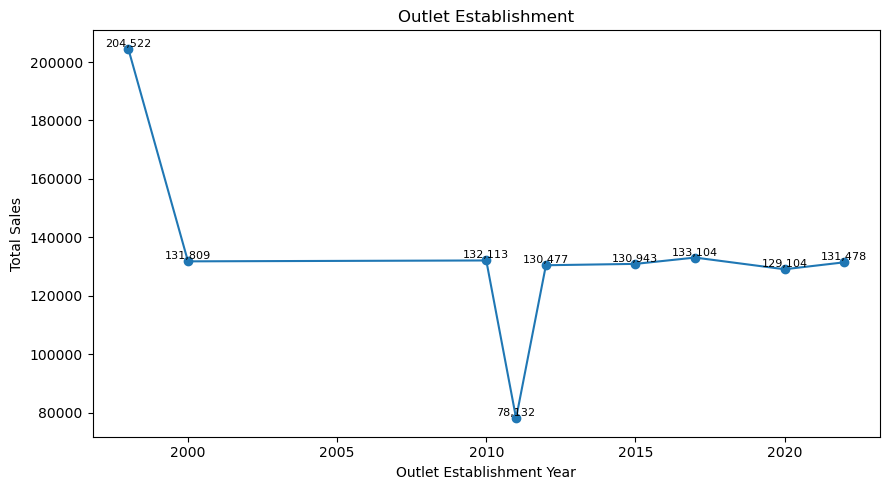

In [49]:
sales_by_year=df.groupby('Outlet Establishment Year')['Sales'].sum().sort_index()

plt.figure(figsize=(9,5))
plt.plot(sales_by_year.index,sales_by_year.values, marker='o', linestyle='-')

plt.xlabel('Outlet Establishment Year')
plt.ylabel('Total Sales')
plt.title('Outlet Establishment')

for x,y in zip(sales_by_year.index,sales_by_year.values):
    plt.text(x, y, f'{y:,.0f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

# sales by outlet size

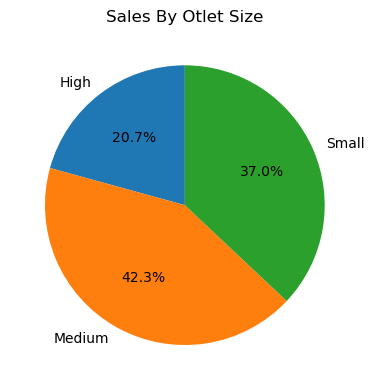

In [92]:
sales_by_size=df.groupby('Outlet Size')['Sales'].sum()

plt.figure(figsize=(4,4))
plt.pie(sales_by_size, labels=sales_by_size.index, autopct='%1.1f%%',startangle=90)
plt.title('Sales By Otlet Size')
plt.tight_layout()
plt.show()

# sales by outlet location

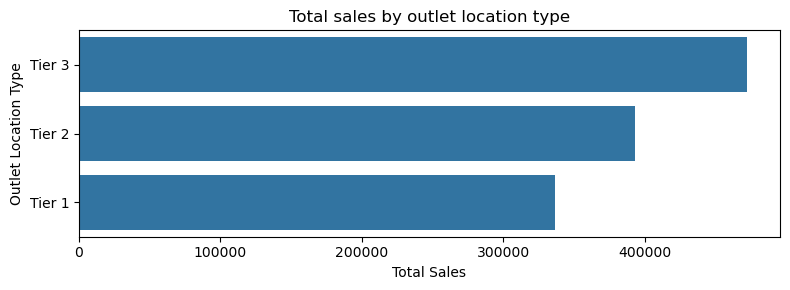

In [56]:
sales_by_location=df.groupby('Outlet Location Type')['Sales'].sum().reset_index()
sales_by_location=sales_by_location.sort_values('Sales', ascending=False)

plt.figure(figsize=(8,3))
ax=sns.barplot(x='Sales', y='Outlet Location Type',data=sales_by_location)

plt.title('Total sales by outlet location type')
plt.xlabel('Total Sales')
plt.ylabel('Outlet Location Type')

plt.tight_layout()
plt.show()

# Sales vs. Outlet Age

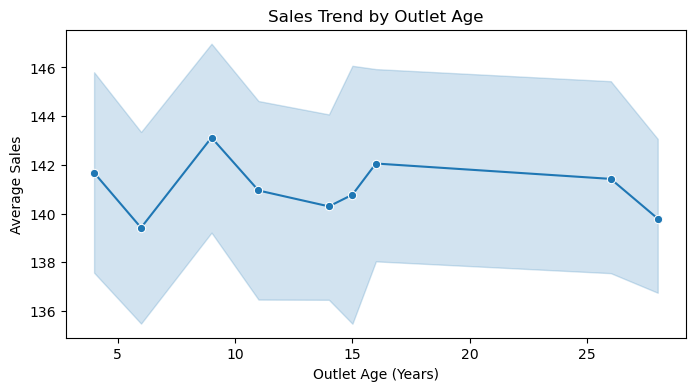

In [93]:
plt.figure(figsize=(8, 4))
sns.lineplot(x='outlet_age', y='Sales', data=df, marker='o')
plt.title('Sales Trend by Outlet Age')
plt.xlabel('Outlet Age (Years)')
plt.ylabel('Average Sales')
plt.show()

# Sales by outlet type

C:\Users\kfb26178\AppData\Local\Temp\ipykernel_15172\630479148.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='Sales', y='Outlet Type', data=df, estimator=sum, ci=None)


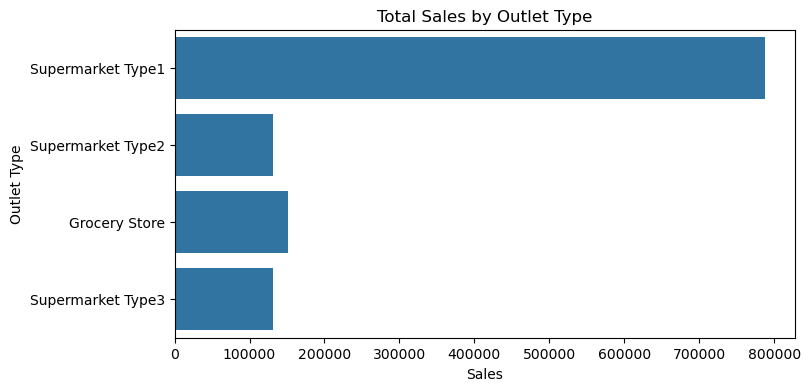

In [96]:
plt.figure(figsize=(8, 4))
sns.barplot(x='Sales', y='Outlet Type', data=df, estimator=sum, ci=None)
plt.title('Total Sales by Outlet Type')
plt.show()

# Item Visibility vs. Sales

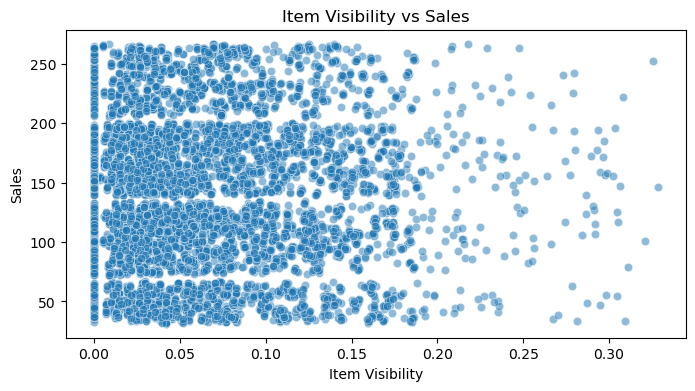

In [97]:
plt.figure(figsize=(8, 4))
sns.scatterplot(x='Item Visibility', y='Sales', data=df, alpha=0.5)
plt.title('Item Visibility vs Sales')
plt.show()

# Correlation Heatmap

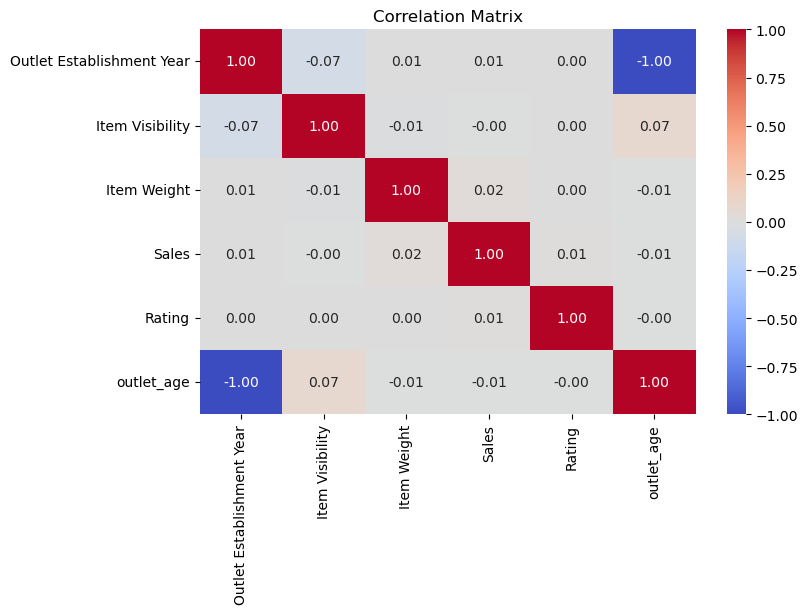

In [98]:
plt.figure(figsize=(8, 5))
sns.heatmap(df.select_dtypes(include=['float64', 'int64']).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

## Building Machine Learning Model

In [100]:
# 2. Create a copy of the dataset to keep the original data intact
df_model = df.copy()

# 3. Define the categorical columns that need to be encoded
categorical_cols = [
    'Item Fat Content', 
    'Item Identifier', 
    'Item Type', 
    'Outlet Identifier', 
    'Outlet Size', 
    'Outlet Location Type', 
    'Outlet Type'
]

# 4. Apply Label Encoding to each categorical column
le = LabelEncoder()
for col in categorical_cols:
    df_model[col] = le.fit_transform(df_model[col])

# 5. Print success message and check the first few rows of the encoded data
print("Data has been successfully encoded for Machine Learning!")
print(df_model.head())

Data has been successfully encoded for Machine Learning!
   Item Fat Content  Item Identifier  Item Type  Outlet Establishment Year  \
0                 1             1142          6                       2012   
1                 0             1280          8                       2022   
2                 1              843          5                       2010   
3                 1              611          3                       2000   
4                 0               82         14                       2015   

   Outlet Identifier  Outlet Location Type  Outlet Size  Outlet Type  \
0                  9                     0            1            1   
1                  3                     2            1            2   
2                  8                     0            2            1   
3                  1                     2            0            1   
4                  7                     1            2            1   

   Item Visibility  Item Weight     Sales

In [102]:
# 1. Separate Features (X) and Target (y)
# (We want to predict 'Sales', so y is Sales and X contains the remaining columns)
X = df_model.drop(columns=['Sales', 'Item Identifier']) # Item Identifier is too unique, so we drop it
y = df_model['Sales']

# 2. Split the data into Training and Testing sets (80% for training, 20% for testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and train the Random Forest Regressor model
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

# 4. Make predictions on the test data
y_pred = model.predict(X_test)

# 5. Evaluate the model performance (R2 Score)
r2 = r2_score(y_test, y_pred)
print(f"R2 Score: {r2:.4f}")

R2 Score: 0.4991


## Feature Importance.

C:\Users\kfb26178\AppData\Local\Temp\ipykernel_15172\1338749821.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')


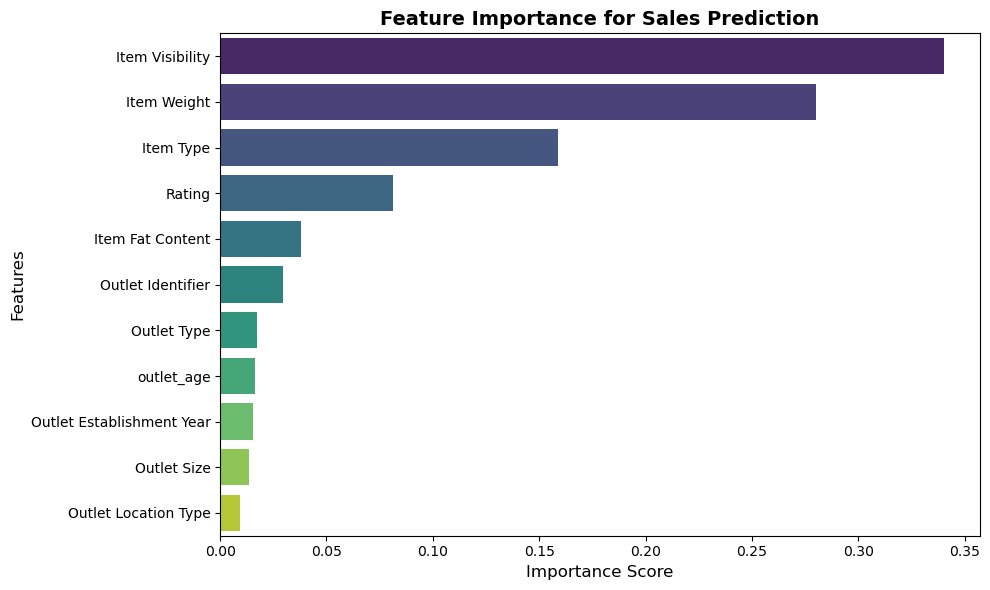

In [103]:
# 1. Get feature importances from the trained model
importances = model.feature_importances_
feature_names = X.columns

# 2. Create a dataframe for visualization
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 3. Plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')
plt.title('Feature Importance for Sales Prediction', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()